# Segmentación de tipos de vehículo con YOLO y Detectron2
**IAM-811 Machine Learning y Aprendizaje Profundo** · Ing. Alvaro Pinto Mamani

Clases objetivo: **Auto particular · Bus · Minibús · Camión**

| Tipo de segmentación | Modelo | ¿Reconoce minibús? |
|---|---|---|
| Instancia | YOLO11-seg (COCO) | No (COCO solo tiene *car, bus, truck*) |
| Instancia, vocabulario abierto | YOLOE-seg con *prompts* de texto | Sí (por texto: "minibus", "van") |
| Instancia | Detectron2 Mask R-CNN (COCO) | No |
| Panóptica | Detectron2 Panoptic FPN | No (pero segmenta además calzada, cielo, etc.) |
| Semántica | Derivada de la panóptica (una máscara por clase) | No |
| Instancia | Modelo propio entrenado (sección 7) | Sí |

> **Nota sobre el minibús:** COCO no tiene la clase minibús, por lo que los modelos preentrenados lo etiquetan como *car*, *bus* o *truck*. Para reconocerlo hay dos caminos: YOLOE con vocabulario abierto (sin entrenar) o un modelo propio entrenado con un dataset de 4 clases (sección 7).

**Antes de empezar:** Entorno de ejecución → Cambiar tipo de entorno → **GPU T4**.

## 1. Instalación

In [1]:
!nvidia-smi -L || echo "Sin GPU: active la GPU T4 en Entorno de ejecución > Cambiar tipo de entorno"
!pip -q install -U ultralytics
# Detectron2 se compila desde el código fuente (5 a 10 minutos la primera vez)
!pip -q install --no-build-isolation 'git+https://github.com/facebookresearch/detectron2.git'

GPU 0: Tesla T4 (UUID: GPU-680a4e7c-c208-c5c3-b5da-3f79ad6d3b8d)
  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (pyproject.toml) ... done


## 2. Configuración y utilidades

In [2]:
import os, time, cv2, numpy as np, torch, pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO, YOLOE

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Dispositivo:', DEVICE)

try:
    from detectron2 import model_zoo
    from detectron2.config import get_cfg
    from detectron2.engine import DefaultPredictor
    from detectron2.data import MetadataCatalog
    from detectron2.utils.visualizer import Visualizer
    HAY_D2 = True
except Exception as e:
    HAY_D2 = False
    print('Detectron2 no disponible, solo se usarán los métodos YOLO:', e)

# Clases internas -> nombre a mostrar
CLASES = {'auto': 'Auto particular', 'bus': 'Bus', 'minibus': 'Minibús', 'camion': 'Camión'}
# Etiquetas sin tildes para dibujar con OpenCV (las fuentes Hershey no tienen tildes)
ETIQUETA_IMG = {'auto': 'Auto', 'bus': 'Bus', 'minibus': 'Minibus', 'camion': 'Camion'}
COLORES = {'auto': (52, 152, 219), 'bus': (231, 76, 60), 'minibus': (46, 204, 113), 'camion': (243, 156, 18)}  # RGB

# Clases COCO que interesan
COCO_A_CLASE = {'car': 'auto', 'bus': 'bus', 'truck': 'camion'}

# Normalización de nombres para un modelo propio
NORMALIZAR = {'auto': 'auto', 'car': 'auto', 'auto particular': 'auto', 'automovil': 'auto', 'vagoneta': 'auto',
              'bus': 'bus', 'minibus': 'minibus', 'minibús': 'minibus', 'van': 'minibus',
              'camion': 'camion', 'camión': 'camion', 'truck': 'camion'}

_cache = {}
def cargar(clave, fabrica):
    if clave not in _cache:
        _cache[clave] = fabrica()
    return _cache[clave]

def caja_de_mascara(m):
    ys, xs = np.where(m)
    if len(xs) == 0:
        return [0, 0, 0, 0]
    return [int(xs.min()), int(ys.min()), int(xs.max()), int(ys.max())]

def dibujar(img_rgb, dets, alpha=0.5, cajas=True):
    capa = img_rgb.copy()
    for d in dets:
        capa[d['mask']] = COLORES[d['clase']]
    out = cv2.addWeighted(capa, alpha, img_rgb, 1 - alpha, 0)
    g = max(2, int(round(max(out.shape[:2]) / 400)))
    for d in dets:
        col = COLORES[d['clase']]
        cnts, _ = cv2.findContours(d['mask'].astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(out, cnts, -1, col, g)
        if cajas:
            x1, y1, x2, y2 = map(int, d['box'])
            cv2.rectangle(out, (x1, y1), (x2, y2), col, g)
            texto = ETIQUETA_IMG[d['clase']] + ' ' + format(d['conf'], '.2f')
            esc, gt = g * 0.35, max(1, g // 2)
            (tw, th), _ = cv2.getTextSize(texto, cv2.FONT_HERSHEY_SIMPLEX, esc, gt)
            cv2.rectangle(out, (x1, max(0, y1 - th - 8)), (x1 + tw + 6, y1), col, -1)
            cv2.putText(out, texto, (x1 + 3, y1 - 5), cv2.FONT_HERSHEY_SIMPLEX, esc, (255, 255, 255), gt, cv2.LINE_AA)
    return out

def resumen(dets, img_shape):
    area_total = img_shape[0] * img_shape[1]
    filas = [{'Clase': CLASES[d['clase']], 'Confianza': round(d['conf'], 3),
              'Área (px)': int(d['mask'].sum()), 'Área (%)': round(100 * d['mask'].sum() / area_total, 2)} for d in dets]
    detalle = pd.DataFrame(filas, columns=['Clase', 'Confianza', 'Área (px)', 'Área (%)'])
    conteo = pd.Series({CLASES[k]: sum(d['clase'] == k for d in dets) for k in CLASES}, name='Cantidad')
    return detalle, conteo

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Dispositivo: cuda


/usr/local/lib/python3.13/dist-packages/detectron2/model_zoo/model_zoo.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## 3. Subir imagen

Saving 2025121810011466138.jpg to 2025121810011466138.jpg
Imagen activa: 2025121810011466138.jpg (558, 992, 3)


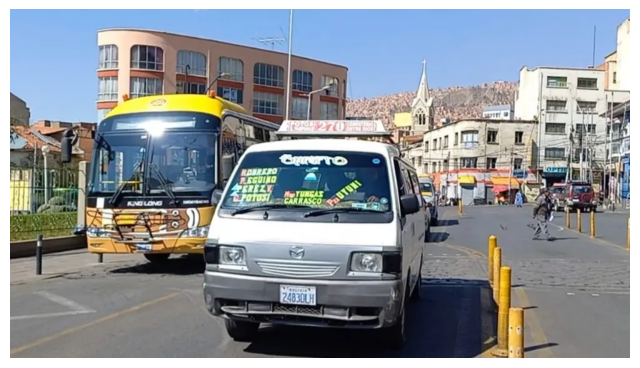

In [3]:
from google.colab import files
subidos = files.upload()   # puede subir una o varias imágenes
IMAGENES = list(subidos.keys())
if not IMAGENES:
    !wget -q -O ejemplo.jpg https://ultralytics.com/images/bus.jpg
    IMAGENES = ['ejemplo.jpg']
IMG_PATH = IMAGENES[0]
img_bgr = cv2.imread(IMG_PATH)
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
print('Imagen activa:', IMG_PATH, img_rgb.shape)
plt.figure(figsize=(8, 6)); plt.imshow(img_rgb); plt.axis('off'); plt.show()

## 4. Métodos de segmentación
Todos devuelven la misma estructura: lista de `{clase, conf, box, mask}` más una imagen adicional opcional (panóptica / mapa semántico).

In [4]:
# ---------- YOLO (Ultralytics) ----------
def yolo_a_dets(r, mapa):
    dets = []
    if r.masks is None:
        return dets
    H, W = r.orig_shape
    clases = r.boxes.cls.cpu().numpy().astype(int)
    confs = r.boxes.conf.cpu().numpy()
    cajas = r.boxes.xyxy.cpu().numpy()
    for poly, c, s, b in zip(r.masks.xy, clases, confs, cajas):
        etiqueta = mapa(r.names[c])
        if etiqueta is None or len(poly) == 0:
            continue
        m = np.zeros((H, W), np.uint8)
        cv2.fillPoly(m, [poly.astype(np.int32)], 1)
        dets.append({'clase': etiqueta, 'conf': float(s), 'box': b.tolist(), 'mask': m.astype(bool)})
    return dets

PESO_YOLO = 'yolo11m-seg.pt'          # n / s / m / l / x
def seg_yolo(img_bgr, conf=0.35):
    m = cargar(PESO_YOLO, lambda: YOLO(PESO_YOLO))
    r = m.predict(img_bgr, conf=conf, device=DEVICE, agnostic_nms=True, verbose=False)[0]
    return yolo_a_dets(r, lambda n: COCO_A_CLASE.get(n)), None

# ---------- YOLOE: vocabulario abierto ----------
# Cada prompt de texto se asigna a una de las 4 clases. Puede agregar o cambiar prompts.
PROMPTS = {'car': 'auto', 'sedan': 'auto',
           'bus': 'bus',
           'minibus': 'minibus', 'van': 'minibus',
           'truck': 'camion', 'cargo truck': 'camion'}
PESO_YOLOE = 'yoloe-11l-seg.pt'
def seg_yoloe(img_bgr, conf=0.25):
    nombres = list(PROMPTS)
    def crear():
        m = YOLOE(PESO_YOLOE)
        m.set_classes(nombres, m.get_text_pe(nombres))
        return m
    m = cargar(PESO_YOLOE + str(tuple(nombres)), crear)
    r = m.predict(img_bgr, conf=conf, device=DEVICE, agnostic_nms=True, verbose=False)[0]
    return yolo_a_dets(r, lambda n: PROMPTS.get(n)), None

# ---------- Detectron2 ----------
def predictor_d2(yaml):
    def crear():
        cfg = get_cfg()
        cfg.merge_from_file(model_zoo.get_config_file(yaml))
        cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(yaml)
        cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.05                     # se filtra después con conf
        cfg.MODEL.PANOPTIC_FPN.COMBINE.INSTANCES_CONFIDENCE_THRESH = 0.05
        cfg.MODEL.DEVICE = DEVICE
        return DefaultPredictor(cfg), MetadataCatalog.get(cfg.DATASETS.TRAIN[0])
    return cargar(yaml, crear)

YAML_MASKRCNN = 'COCO-InstanceSegmentation/mask_rcnn_R_101_FPN_3x.yaml'
YAML_PANOPTIC = 'COCO-PanopticSegmentation/panoptic_fpn_R_101_3x.yaml'

def seg_maskrcnn(img_bgr, conf=0.5):
    pred, meta = predictor_d2(YAML_MASKRCNN)
    inst = pred(img_bgr)['instances'].to('cpu')
    dets = []
    for c, s, b, m in zip(inst.pred_classes.numpy(), inst.scores.numpy(),
                          inst.pred_boxes.tensor.numpy(), inst.pred_masks.numpy()):
        etiqueta = COCO_A_CLASE.get(meta.thing_classes[c])
        if etiqueta and s >= conf:
            dets.append({'clase': etiqueta, 'conf': float(s), 'box': b.tolist(), 'mask': m.astype(bool)})
    return dets, None

def _panoptico(img_bgr):
    pred, meta = predictor_d2(YAML_PANOPTIC)
    seg, info = pred(img_bgr)['panoptic_seg']
    return seg.cpu(), info, meta

def seg_panoptica(img_bgr, conf=0.5):
    seg, info, meta = _panoptico(img_bgr)
    seg_np = seg.numpy()
    dets, info_vis = [], []
    for s in info:
        if s['isthing']:
            if s.get('score', 1.0) < conf:
                continue
            etiqueta = COCO_A_CLASE.get(meta.thing_classes[s['category_id']])
            if etiqueta:
                m = seg_np == s['id']
                dets.append({'clase': etiqueta, 'conf': float(s.get('score', 1.0)), 'box': caja_de_mascara(m), 'mask': m})
        info_vis.append(s)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    vis = Visualizer(img_rgb, meta, scale=1.0).draw_panoptic_seg(seg, info_vis).get_image()
    return dets, ('Escena completa (cosas + regiones)', vis)

def seg_semantica(img_bgr, conf=0.5):
    # Semántica: una sola máscara por clase, sin separar instancias
    seg, info, meta = _panoptico(img_bgr)
    seg_np = seg.numpy()
    mapa = np.zeros(seg_np.shape + (3,), np.uint8)
    por_clase = {}
    for s in info:
        m = seg_np == s['id']
        if s['isthing']:
            etiqueta = COCO_A_CLASE.get(meta.thing_classes[s['category_id']])
            if etiqueta and s.get('score', 1.0) >= conf:
                por_clase.setdefault(etiqueta, []).append((m, s.get('score', 1.0)))
        else:
            v = 50 + (s['category_id'] * 37) % 130          # regiones (calzada, cielo...) en grises
            mapa[m] = (v, v, v)
    dets = []
    for k, lista in por_clase.items():
        union = np.any([m for m, _ in lista], axis=0)
        mapa[union] = COLORES[k]
        dets.append({'clase': k, 'conf': float(np.mean([s for _, s in lista])), 'box': caja_de_mascara(union), 'mask': union})
    regiones = sorted({meta.stuff_classes[s['category_id']] for s in info if not s['isthing']})
    return dets, ('Mapa semántico · regiones: ' + ', '.join(regiones), mapa)

# ---------- Modelo propio (ver sección 7) ----------
RUTA_MODELO_PROPIO = '/content/runs/segment/vehiculos/weights/best.pt'
def seg_propio(img_bgr, conf=0.35):
    m = cargar(RUTA_MODELO_PROPIO, lambda: YOLO(RUTA_MODELO_PROPIO))
    r = m.predict(img_bgr, conf=conf, device=DEVICE, agnostic_nms=True, verbose=False)[0]
    return yolo_a_dets(r, lambda n: NORMALIZAR.get(n.strip().lower())), None

def metodos_disponibles():
    met = {'Instancia · YOLO11-seg (COCO)': seg_yolo,
           'Instancia · YOLOE vocabulario abierto (con minibús)': seg_yoloe}
    if HAY_D2:
        met['Instancia · Detectron2 Mask R-CNN'] = seg_maskrcnn
        met['Panóptica · Detectron2 Panoptic FPN'] = seg_panoptica
        met['Semántica · por clase (Detectron2)'] = seg_semantica
    if os.path.exists(RUTA_MODELO_PROPIO):
        met['Instancia · Modelo propio (4 clases)'] = seg_propio
    return met

def ejecutar(nombre, img_bgr, conf, alpha=0.5, guardar=True):
    fn = metodos_disponibles()[nombre]
    t0 = time.time()
    dets, extra = fn(img_bgr, conf)
    dt = time.time() - t0
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    vis = dibujar(img_rgb, dets, alpha, cajas=not nombre.startswith('Semántica'))
    paneles = [('Original', img_rgb), (nombre, vis)] + ([extra] if extra else [])
    fig, ax = plt.subplots(1, len(paneles), figsize=(7 * len(paneles), 6))
    for a, (t, im) in zip(ax, paneles):
        a.imshow(im); a.set_title(t, fontsize=10); a.axis('off')
    plt.tight_layout(); plt.show()
    detalle, conteo = resumen(dets, img_bgr.shape)
    print('Tiempo de inferencia: ' + format(dt, '.2f') + ' s')
    display(conteo.to_frame().T); display(detalle)
    if guardar:
        os.makedirs('/content/resultados', exist_ok=True)
        base = os.path.splitext(os.path.basename(IMG_PATH))[0]
        sufijo = nombre.split('·')[1].strip().split(' ')[0].lower()
        cv2.imwrite('/content/resultados/' + base + '_' + sufijo + '.jpg', cv2.cvtColor(vis, cv2.COLOR_RGB2BGR))
    return dets

## 5. Interfaz: elegir imagen, método y umbral

In [5]:
import ipywidgets as w
from IPython.display import display, clear_output

def leer_fileupload(valor):
    # Compatible con ipywidgets 7 (dict) y 8 (tupla)
    items = valor.values() if isinstance(valor, dict) else valor
    res = []
    for it in items:
        nombre = it.get('name') or it.get('metadata', {}).get('name', 'subida.jpg')
        res.append((nombre, bytes(it['content'])))
    return res

subir = w.FileUpload(accept='image/*', multiple=True, description='Subir imagen')
selector_img = w.Dropdown(options=IMAGENES, value=IMG_PATH, description='Imagen:', layout=w.Layout(width='420px'))
selector_met = w.Dropdown(options=list(metodos_disponibles()), description='Método:', layout=w.Layout(width='520px'))
umbral = w.FloatSlider(value=0.40, min=0.05, max=0.95, step=0.05, description='Confianza:')
opacidad = w.FloatSlider(value=0.50, min=0.1, max=0.9, step=0.05, description='Opacidad:')
boton = w.Button(description='Segmentar', button_style='primary', icon='play')
salida = w.Output()

def al_subir(cambio):
    for nombre, contenido in leer_fileupload(subir.value):
        with open(nombre, 'wb') as f:
            f.write(contenido)
        if nombre not in IMAGENES:
            IMAGENES.append(nombre)
    selector_img.options = IMAGENES
    selector_img.value = IMAGENES[-1]

def al_pulsar(_):
    global IMG_PATH
    IMG_PATH = selector_img.value
    with salida:
        clear_output(wait=True)
        print('Procesando... (la primera vez descarga los pesos del modelo)')
        img = cv2.imread(IMG_PATH)
        clear_output(wait=True)
        ejecutar(selector_met.value, img, umbral.value, opacidad.value)

subir.observe(al_subir, names='value')
boton.on_click(al_pulsar)
display(w.VBox([w.HBox([subir, selector_img]), selector_met, w.HBox([umbral, opacidad]), boton, salida]))

## 6. Comparación de todos los métodos sobre la misma imagen

requirements: Ultralytics requirement ['git+https://github.com/ultralytics/CLIP.git'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 37 packages in 916ms
Prepared 2 packages in 2.91s
Installed 2 packages in 1ms
 + clip==1.0 (from git+https://github.com/ultralytics/CLIP.git@7ffa84b3bfa40c42ecc1c77147a855e69cb2dd40)
 + ftfy==6.3.1

requirements: AutoUpdate success ✅ 4.4s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect



/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(
model_final_a3ec72.pkl: 254MB [00:00, 269MB/s]                           
/usr/local/lib/python3.13/dist-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/TensorShape.cpp:4221.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
W1119 00:13:02.428000 1169 torch/fx/_symbolic_trace.py:57] is_fx_tracing will return true for both fx.symbolic_trace and torch.export. Please use is_fx_tracing_symbolic_tracing() for specifically fx.symbolic_trace or torch.compiler.is_compiling() for specifically torch.export/compile.
model_final_cafdb1.pkl: 261MB [00:01, 229MB/s]                           


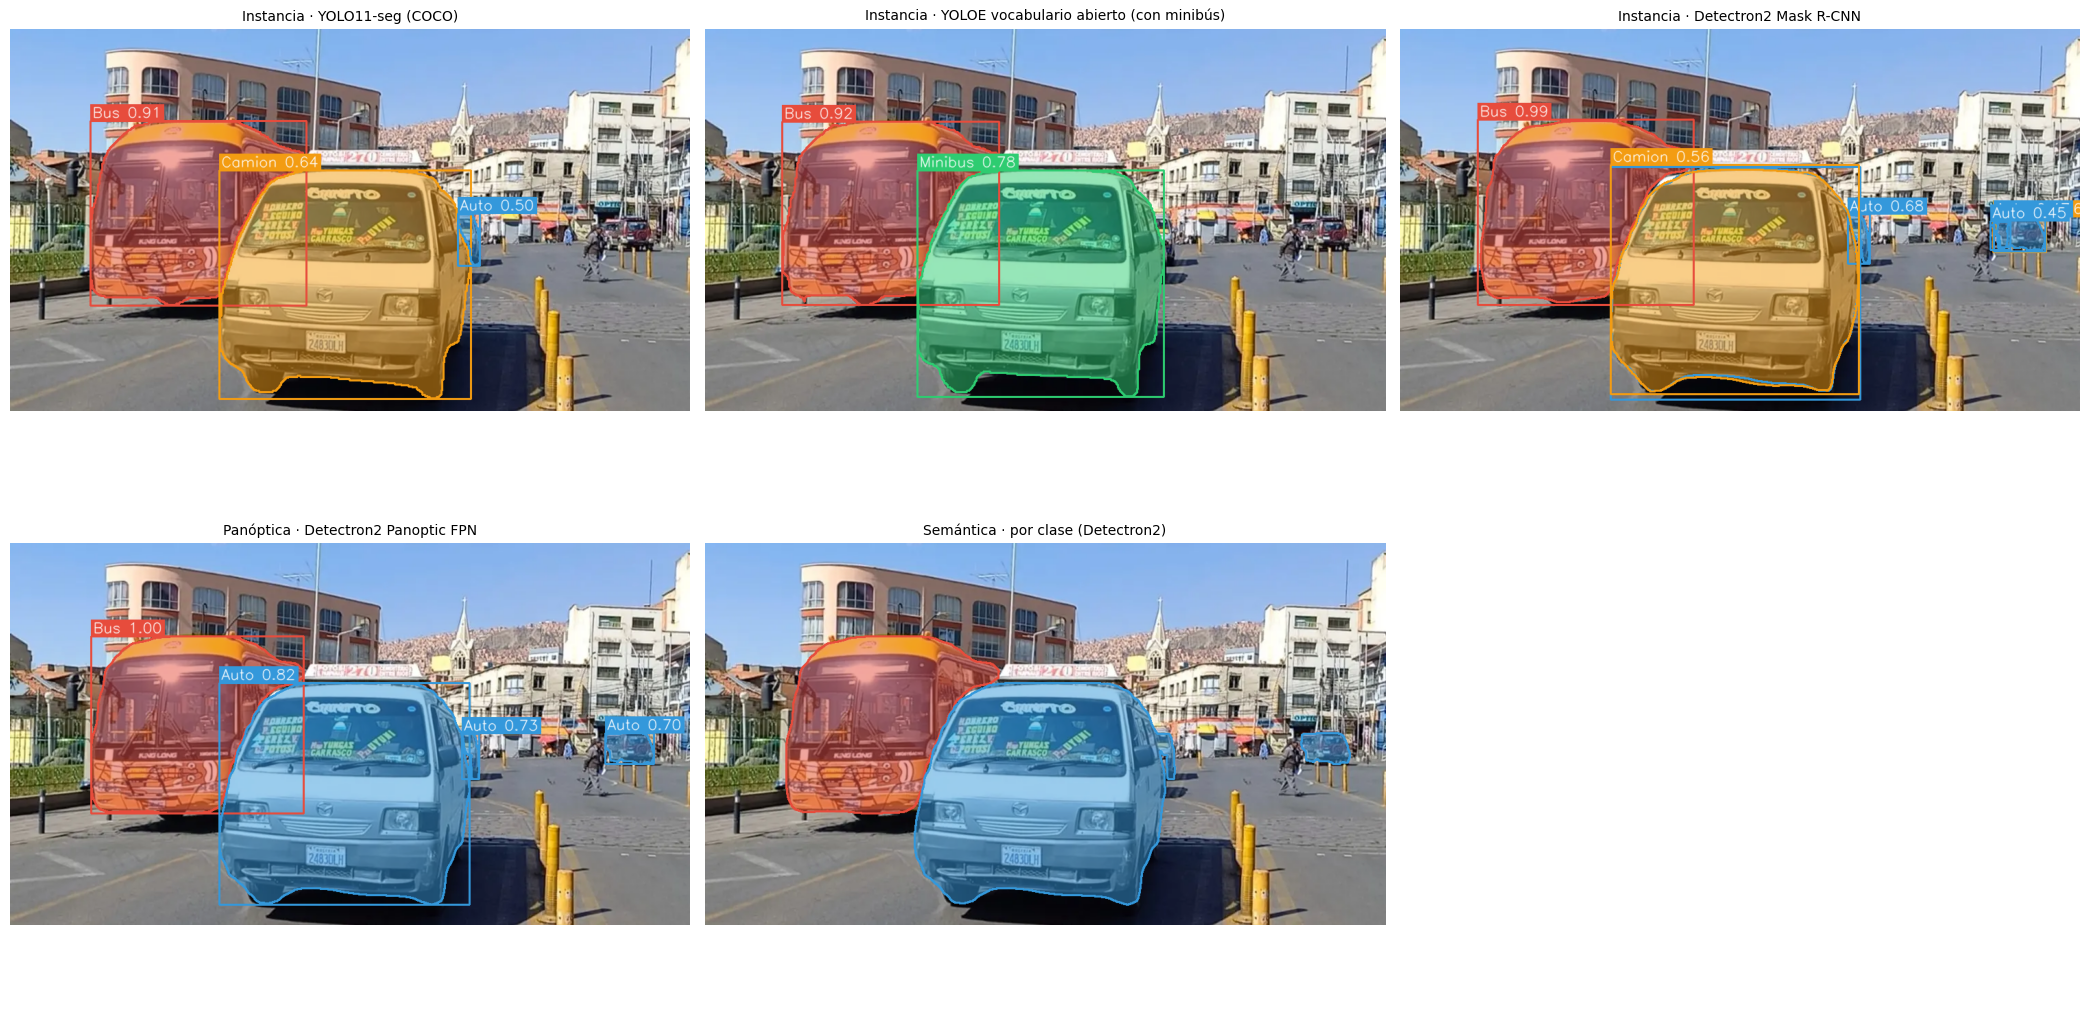

,Auto particular,Bus,Minibús,Camión,Tiempo (s)
Método,,,,,
Instancia · YOLO11-seg (COCO),1,1,0,1,6.50
Instancia · YOLOE vocabulario abierto (con minibús),0,1,1,0,26.01
Instancia · Detectron2 Mask R-CNN,4,1,0,2,2.79
Panóptica · Detectron2 Panoptic FPN,3,1,0,0,4.62
Semántica · por clase (Detectron2),1,1,0,0,0.24


In [6]:
CONF = 0.40
img = cv2.imread(IMG_PATH)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
met = metodos_disponibles()
tabla, vistas = [], []
for nombre, fn in met.items():
    t0 = time.time()
    dets, _ = fn(img, CONF)
    dt = time.time() - t0
    vistas.append((nombre, dibujar(img_rgb, dets, cajas=not nombre.startswith('Semántica'))))
    _, conteo = resumen(dets, img.shape)
    fila = conteo.to_dict(); fila['Método'] = nombre; fila['Tiempo (s)'] = round(dt, 2)
    tabla.append(fila)

cols = 3
filas = int(np.ceil(len(vistas) / cols))
fig, ax = plt.subplots(filas, cols, figsize=(7 * cols, 5.5 * filas))
ax = np.array(ax).reshape(-1)
for a in ax: a.axis('off')
for a, (t, im) in zip(ax, vistas):
    a.imshow(im); a.set_title(t, fontsize=10)
plt.tight_layout(); plt.show()
display(pd.DataFrame(tabla).set_index('Método'))
# Nota: el tiempo de la primera ejecución de cada método incluye la carga del modelo.